In [12]:
# !pip install scikit-optimize

In [13]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from sklearn import svm
from sklearn.model_selection import KFold, cross_val_score

from skopt import BayesSearchCV

from skopt.space import Real, Categorical

In [14]:
data = pd.read_csv("diabetes.csv")

values = data.values


In [15]:
X = values[:,0:8]
y = values[:,8]


In [16]:
X

array([[  6.   , 148.   ,  72.   , ...,  33.6  ,   0.627,  50.   ],
       [  1.   ,  85.   ,  66.   , ...,  26.6  ,   0.351,  31.   ],
       [  8.   , 183.   ,  64.   , ...,  23.3  ,   0.672,  32.   ],
       ...,
       [  5.   , 121.   ,  72.   , ...,  26.2  ,   0.245,  30.   ],
       [  1.   , 126.   ,  60.   , ...,  30.1  ,   0.349,  47.   ],
       [  1.   ,  93.   ,  70.   , ...,  30.4  ,   0.315,  23.   ]],
      shape=(768, 8))

In [17]:
y

array([1., 0., 1., 0., 1., 0., 1., 0., 1., 1., 0., 1., 0., 1., 1., 1., 1.,
       1., 0., 1., 0., 0., 1., 1., 1., 1., 1., 0., 0., 0., 0., 1., 0., 0.,
       0., 0., 0., 1., 1., 1., 0., 0., 0., 1., 0., 1., 0., 0., 1., 0., 0.,
       0., 0., 1., 0., 0., 1., 0., 0., 0., 0., 1., 0., 0., 1., 0., 1., 0.,
       0., 0., 1., 0., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1.,
       0., 0., 0., 1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1., 1., 0.,
       0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 0., 0., 1., 1., 1., 0., 0.,
       0., 1., 0., 0., 0., 1., 1., 0., 0., 1., 1., 1., 1., 1., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 1.,
       0., 1., 1., 0., 0., 0., 1., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0.,
       1., 1., 0., 0., 0., 1., 0., 1., 0., 1., 0., 0., 0., 0., 0., 1., 1.,
       1., 1., 1., 0., 0., 1., 1., 0., 1., 0., 1., 1., 1., 0., 0., 0., 0.,
       0., 0., 1., 1., 0., 1., 0., 0., 0., 1., 1., 1., 1., 0., 1., 1., 1.,
       1., 0., 0., 0., 0.

In [18]:

clf = svm.SVC(C=1.0, kernel='rbf', gamma='scale')

clf.fit(X,y)

print("Baseline Training Accuracy:", clf.score(X,y))


Baseline Training Accuracy: 0.7682291666666666


In [19]:

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

result = cross_val_score(clf, X, y, cv=kfold, scoring='accuracy', n_jobs=-1)

print("Cross-val scores:", result)
print("Mean CV accuracy:", result.mean())


Cross-val scores: [0.76623377 0.76623377 0.74675325 0.73856209 0.73202614]
Mean CV accuracy: 0.7499618029029793


In [20]:

search_spaces = {
    'C': Real(1e-3, 1e+3, prior='log-uniform'),       # C varies logarithmically
    'gamma': Real(1e-4, 1e+1, prior='log-uniform'),   # gamma varies logarithmically
    'kernel': Categorical(['linear', 'rbf', 'sigmoid'])
}

search_spaces

{'C': Real(low=0.001, high=1000.0, prior='log-uniform', transform='identity'),
 'gamma': Real(low=0.0001, high=10.0, prior='log-uniform', transform='identity'),
 'kernel': Categorical(categories=('linear', 'rbf', 'sigmoid'), prior=None)}

In [21]:
opt = BayesSearchCV( 
    estimator=svm.SVC(),
    search_spaces=search_spaces,
    n_iter=10,                
    cv=5,                     
    n_jobs=-1,
    scoring='accuracy'
)

import time
start_time = time.time()
opt.fit(X, y)

print("Best CV Score: %f" % opt.best_score_)
print("Best Parameters:", opt.best_params_)

print("Execution time:", str((time.time() - start_time)) + " sec")

Best CV Score: 0.763102
Best Parameters: OrderedDict({'C': 56.25406479375852, 'gamma': 1.0051441496099203, 'kernel': 'linear'})
Execution time: 506.6014621257782 sec


Best CV Score: 0.7631016042780748
Best Parameters: OrderedDict({'C': 56.25406479375852, 'gamma': 1.0051441496099203, 'kernel': 'linear'})


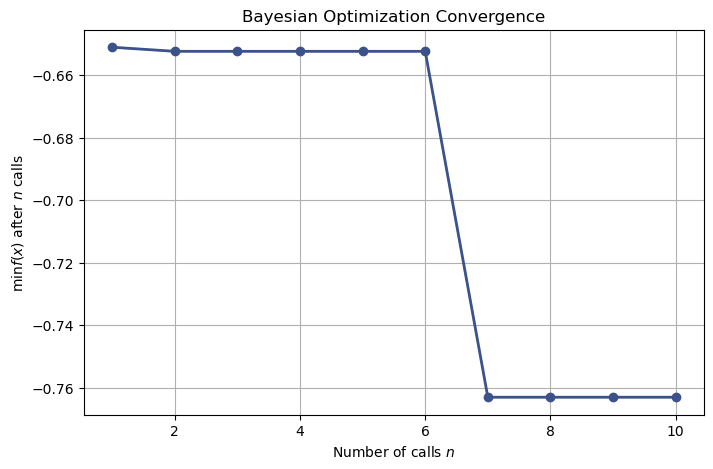

In [22]:

import matplotlib.pyplot as plt

from skopt.plots import plot_convergence

print("Best CV Score:", opt.best_score_)
print("Best Parameters:", opt.best_params_)

plt.figure(figsize=(8,5))
plot_convergence(opt.optimizer_results_)
plt.title("Bayesian Optimization Convergence")
plt.grid(True)
plt.show()
